# S10 · Copula 拟合与选择：AIC 能告诉你什么，不能告诉你什么

> **Day 10 / 14** ｜ 对应论文章节 **3.7.3 + 4.3（Objective 3）**
>
> ⚠️ 模拟数据，结果仅用于验证流程。

---

## 学习目标

- 用 MPL（maximum pseudo-likelihood）拟合六个 copula 族
- 读懂 AIC 表，并用「隐含 τ」自检拟合是否正确
- 计算并解释**尾部依赖系数** λ
- 认识到 **ΔAIC < 2 时数据无法区分模型** —— 并知道这时论文该怎么写

---

## 1. 加载

In [1]:
for (p in c("00_setup.R", "notebooks/00_setup.R", "../00_setup.R")) {
  if (file.exists(p)) { source(p); break }
}


[00_setup.R] 已加载
  项目根目录 : C:/Users/User/Desktop/Jz/UTM/UGRP
  基准期     : 1985-2014
  阈值       : 90百分位, ±7天滑窗
  事件规则   : 最短 3 天, 合并间隔 ≤ 2 天
  干/湿切点  : ARP < 30 / > 50


In [2]:
uv <- readRDS(file.path(PATHS$mres, "S09_pit_pairs.rds"))

U      <- as.matrix(uv[, c("u", "v")])        # 中点 PIT，用于拟合
U_rand <- as.matrix(uv[, c("u_rand", "v")])   # 随机化 PIT，用于敏感性检验

cat("n =", nrow(U), "\n")
cat("样本 Kendall tau =", round(cor(U[, 1], U[, 2], method = "kendall"), 4), "\n")

n = 90 


样本 Kendall tau = 0.2951 


---

## 2. 为什么用 MPL 而不是 ML

`semi-parametric` 的两步法：

1. 边缘用经验 PIT（不假设参数形式）→ 得到 `U`
2. 在 `U` 上最大化**伪似然**（pseudo-likelihood）

$$\ell(\theta) = \sum_{i=1}^{n} \log c_\theta(U_{i1}, U_{i2})$$

**为什么不用完整 ML？** 完整 ML 需要同时估计边缘参数和 copula 参数，两者会互相干扰，且对边缘的误设极其敏感。MPL 在边缘正确、copula 正确时是一致估计（Genest et al., 1995），是气候极值文献的标准做法。

In [3]:
base_cop <- list(
  Gaussian = copula::normalCopula(0.4, dim = 2),
  t        = copula::tCopula(0.4, dim = 2, df = 4),
  Clayton  = copula::claytonCopula(1, dim = 2),
  Gumbel   = copula::gumbelCopula(1.5, dim = 2),
  Frank    = copula::frankCopula(2, dim = 2),
  Joe      = copula::joeCopula(1.5, dim = 2)
)
FAMS <- names(base_cop)

---

## 3. 拟合六个族

In [4]:
fit_all <- function(X) {
  do.call(rbind, lapply(FAMS, function(f) {
    fit <- tryCatch(suppressWarnings(copula::fitCopula(base_cop[[f]], X, method = "mpl")),
                    error = function(e) NULL)
    if (is.null(fit)) return(data.frame(family = f, k = NA, logLik = NA,
                                        AIC = NA, tau_fit = NA, par = NA))
    cop <- fit@copula
    ll  <- as.numeric(logLik(fit))
    k   <- length(copula::coef(fit))
    data.frame(family   = f,
               k        = k,
               logLik   = round(ll, 2),
               AIC      = round(-2 * ll + 2 * k, 2),
               tau_fit  = round(as.numeric(copula::tau(cop)), 4),
               par      = paste(round(copula::coef(fit), 3), collapse = ", "))
  }))
}

fits <- fit_all(U)
fits$dAIC <- round(fits$AIC - min(fits$AIC, na.rm = TRUE), 2)
print(fits[, c("family", "k", "logLik", "AIC", "dAIC", "tau_fit", "par")], row.names = FALSE)

   family k logLik    AIC dAIC tau_fit           par
 Gaussian 1   8.64 -15.29 0.00  0.3021         0.457
        t 2   8.74 -13.49 1.80  0.2996 0.453, 20.067
  Clayton 1   4.86  -7.72 7.57  0.2951         0.837
   Gumbel 1   8.11 -14.21 1.08  0.2559         1.344
    Frank 1   7.42 -12.84 2.45  0.2822         2.719
      Joe 1   7.07 -12.14 3.15  0.1997         1.443


> 🔍 **先做自检，再看排名**：`tau_fit` 这一列应当都接近样本的 τ（≈ 0.295）。
> 本例中 Joe 只到 0.20 —— 说明在 τ = 0.30 这个强度上，Joe 族的参数化表达不出观测到的依赖，
> **该族不适合这份数据**（注意不是「拟合失败」：优化收敛了，只是形状对不上）。
>
> 这张表本身就是一个小结论：**候选集里不是每个族都「够得着」你的数据。**
>
> 另一个常见现象：Gaussian 的 `par` 是 ρ，Gumbel 的 `par` 是 α，它们**不能直接比较大小**，
> 只能通过 `tau` 换算到同一尺度。

---

## 4. 尾部依赖：这才是极端事件研究真正要看的

In [5]:
tail_tab <- do.call(rbind, lapply(seq_len(nrow(fits)), function(i) {
  f   <- fits$family[i]
  cop <- suppressWarnings(copula::fitCopula(base_cop[[f]], U, method = "mpl"))@copula
  td  <- tail_dep(tolower(f), cop)
  data.frame(family = f, AIC = fits$AIC[i],
             lambda_L = round(td["lower"], 3), lambda_U = round(td["upper"], 3))
}))
print(tail_tab, row.names = FALSE)

   family    AIC lambda_L lambda_U
 Gaussian -15.29    0.000    0.000
        t -13.49    0.011    0.011
  Clayton  -7.72    0.437    0.000
   Gumbel -14.21    0.000    0.325
    Frank -12.84    0.000    0.000
      Joe -12.14    0.000    0.383


> 📌 **λ 的读法**：
> - λ = 0：两个变量在极端处**渐近独立** —— 「长」和「强」不会一起走到最极端
> - λ = 0.3：在极端分位上，一个变量很高时，另一个也很高的条件概率约 30%
>
> **注意 λ 是模型属性，不是数据属性。** 同一批数据，选 Gaussian 得到 λ_U = 0，
> 选 Gumbel 可能得到 λ_U = 0.3。这不是矛盾，这是**模型不确定性**。

---

## 5. 拟合优度：参数 bootstrap

只看 AIC 不够 —— AIC 只在**候选集内部**排名，不告诉你「最好的那个是不是够好」。

In [6]:
gof_one <- function(f, cop, X, N = 150) {
  cp <- cop
  if (f == "t") {
    # pCopula 不支持非整数 df，GoF 时必须固定 df
    cp <- copula::tCopula(cop@parameters[1], dim = 2,
                          df = round(cop@parameters[2]), df.fixed = TRUE)
  }
  out <- tryCatch(suppressWarnings(copula::gofCopula(cp, X, N = N)),
                  error = function(e) NULL)
  if (is.null(out)) return(c(stat = NA_real_, p = NA_real_))
  c(stat = as.numeric(out$statistic), p = as.numeric(out$p.value))
}

gof_tab <- do.call(rbind, lapply(seq_len(nrow(fits)), function(i) {
  f   <- fits$family[i]
  cop <- suppressWarnings(copula::fitCopula(base_cop[[f]], U, method = "mpl"))@copula
  g   <- gof_one(f, cop, U, N = 150)
  data.frame(family = f, CvM = round(g["stat"], 4), p_gof = round(g["p"], 3))
}))
print(gof_tab, row.names = FALSE)

   family    CvM p_gof
 Gaussian 0.0216 0.427
        t 0.0208 0.474
  Clayton 0.0436 0.043
   Gumbel 0.0167 0.738
    Frank 0.0290 0.248
      Joe 0.0268 0.321


> ⚠️ **`p_gof` 大于 0.05 只说明「没有足够证据拒绝」，不说明「模型正确」。**
> n = 90 时，参数 bootstrap 的检验力很弱 —— 几乎任何合理的族都不会被拒绝。
> **所以这一列的作用是排除明显糟糕的候选，不能用来选优。**
>
> 另外注意：某些族的 bootstrap 重估会碰到参数边界（典型是 Clayton 在弱依赖时），
> 此时返回 `NA`。这是实现限制，不是数据问题，**在论文里要如实说明**。

---

## 6. 选择：AIC 的排名什么时候有意义

In [7]:
best <- fits[which.min(fits$AIC), ]
close_models <- fits[fits$dAIC < 2, "family"]

cat("AIC 最小:", best$family, "\n")
cat("ΔAIC < 2 的族:", paste(close_models, collapse = ", "), "\n")
cat("\n这些族的 lambda_U 跨度:",
    paste(round(tail_tab$lambda_U[tail_tab$family %in% close_models], 3),
          collapse = " / "), "\n")

AIC 最小: Gaussian 


ΔAIC < 2 的族: Gaussian, t, Gumbel 



这些族的 lambda_U 跨度: 0 / 0.011 / 0.325 


> 🚨 **这张表是整篇论文方法论上最关键的一处张力。**
>
> 如果 ΔAIC < 2 的几个族在 λ_U 上差了 0.3 以上，那么：
> **「尾部依赖有多强」这个核心结论，主要取决于你选了哪个 copula 族，而不取决于数据。**
>
> 这不是本手册的缺陷，这是小样本极值 copula 分析普遍的困境。处理方式有三种，都必须在论文里写清楚：
>
> | 策略 | 做法 | 适用 |
> |---|---|---|
> | **A. 集成报告** | 不选唯一模型，把 ΔAIC < 2 的族全部带进 S12，报告重现期的**区间** | ✅ 本手册采用 |
> | B. 加权平均 | 用 Akaike 权重做模型平均 | 需要更多模型族 |
> | C. 先验约束 | 依物理机制排除不该有尾依赖的族 | 有强理论依据时 |
>
> **绝对不要做的事**：只报 AIC 最小的那个族的 λ_U，然后写「本区域存在显著的湿热复合尾部依赖」。
> 审稿人只要换一个族重跑，你的结论就没了。

---

## 7. 敏感性：换一个 PIT 版本会怎样

In [8]:
fits_rand <- fit_all(U_rand)

sens <- merge(fits[, c("family", "AIC", "tau_fit")],
              fits_rand[, c("family", "AIC", "tau_fit")],
              by = "family", suffixes = c("_mid", "_rand"))
sens$d_tau <- round(sens$tau_fit_rand - sens$tau_fit_mid, 4)
print(sens[, c("family", "tau_fit_mid", "tau_fit_rand", "d_tau")], row.names = FALSE)

   family tau_fit_mid tau_fit_rand   d_tau
  Clayton      0.2951       0.2316 -0.0635
    Frank      0.2822       0.2383 -0.0439
 Gaussian      0.3021       0.2454 -0.0567
   Gumbel      0.2559       0.2233 -0.0326
      Joe      0.1997       0.1907 -0.0090
        t      0.2996       0.2454 -0.0542


> 🔍 **预期看到所有族的 `d_tau` 都是负数，且大致与各自的 τ 成比例**（τ 越大，被稀释得越多）。
> 这证实了 S09 的结论：随机化 PIT 稀释的是**数据层面的秩信息**，不是某个族的拟合问题。
> 如果某个族的 `d_tau` 是正的，那才是异常 —— 说明拟合有问题。
>
> 论文写法：「Fit on mid-interval PIT (Kendall τ = 0.295) yields nearly identical copula parameters;
> using randomised PIT attenuates τ to 0.255 ± 0.018, consistent with the tie fraction of the
> discrete duration margin (39% of events share the minimum duration of 3 days).」
> —— 这句话直接把审稿人可能提出的质疑变成你的稳健性证据。

---

## 8. 图：观测 vs 拟合模型

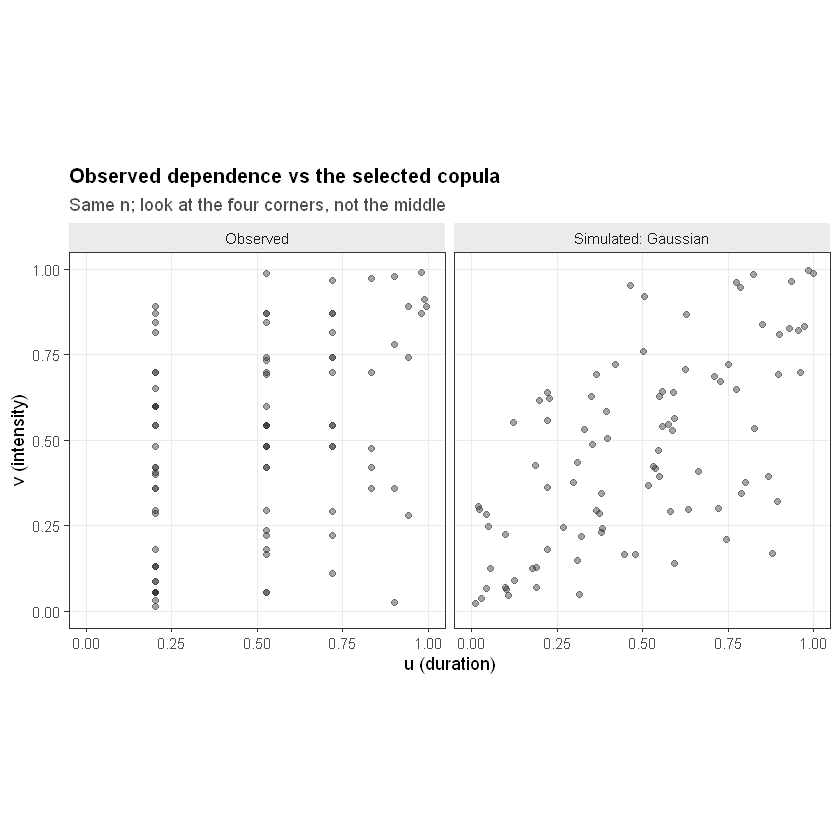

In [9]:
primary <- best$family
cop_best <- suppressWarnings(copula::fitCopula(base_cop[[primary]], U, method = "mpl"))@copula

set.seed(CFG$seed)
sim <- copula::rCopula(nrow(U), cop_best)

ov <- rbind(
  data.frame(u = U[, 1], v = U[, 2], src = "Observed"),
  data.frame(u = sim[, 1], v = sim[, 2], src = paste("Simulated:", primary))
)

p_fit <- ggplot(ov, aes(u, v)) +
  geom_point(alpha = 0.45, size = 1.5, colour = "grey20") +
  facet_wrap(~src) +
  coord_equal(xlim = c(0, 1), ylim = c(0, 1)) +
  labs(x = "u (duration)", y = "v (intensity)",
       title = "Observed dependence vs the selected copula",
       subtitle = "Same n; look at the four corners, not the middle") +
  theme_paper()

save_fig(p_fit, "S10_fit_check", 7.2, 3.8)
p_fit

> 🔍 **对照时只看四个角**。中间区域几乎所有的椭圆族都能拟合得不错，
> 差别全部体现在角上 —— 而角正是「复合极端事件」的定义所在。

---

## 9. 保存

In [10]:
fit_res <- list(
  U = U, U_rand = U_rand,
  table = fits, tail = tail_tab, gof = gof_tab,
  primary = primary,
  copulas = lapply(FAMS, function(f)
    suppressWarnings(copula::fitCopula(base_cop[[f]], U, method = "mpl"))@copula)
)
names(fit_res$copulas) <- FAMS
saveRDS(fit_res, file.path(PATHS$mres, "S10_copula_fits.rds"))

write.csv(fits, file.path(PATHS$mres, "table3_copula_selection.csv"), row.names = FALSE)
write.csv(tail_tab, file.path(PATHS$mres, "table3b_tail_dependence.csv"), row.names = FALSE)
cat("已保存 S10_copula_fits.rds 与两张 CSV\n")

已保存 S10_copula_fits.rds 与两张 CSV


---

## 10. 常见错误

| 错误 | 后果 |
|---|---|
| 用 ML 同时估边缘和 copula | 参数互相干扰，且对边缘误设敏感 |
| 比较不同族的原始参数（ρ vs α） | 尺度不同，毫无意义 |
| 只报 AIC 最优族的 λ_U | 结论由模型选择决定，不可复现 |
| 把 `p_gof > 0.05` 当作「模型正确」 | 小样本检验力弱，几乎什么都不会被拒 |
| 忽略 ΔAIC < 2 的模型 | 隐藏了模型不确定性 |
| 不检查 `tau_fit` 与样本 τ 是否一致 | 拟合错位却看不出来 |
| 把 λ 当作数据属性报告 | λ 是模型属性，必须说明所依赖的模型 |

---

## 11. 自检问题

<details>
<summary>Q1：为什么 Gaussian 和 t 的 `par` 都是相关系数，τ 却不同？</summary>

因为 τ 与 ρ 的关系不同：Gaussian 下 $\tau = \frac{2}{\pi}\arcsin\rho$，t copula 在 df 有限时同一 ρ 对应略小的 τ。df 越小差异越大。所以比较必须换算到 τ 或 λ，不能比 ρ。

</details>

<details>
<summary>Q2：ΔAIC = 1.8 说明第一个模型「更好」吗？</summary>

不。ΔAIC < 2 通常被视为「无实质差别」。AIC 估计的是预测损失，1.8 个单位的差异在 n = 90 的抽样误差范围之内。正确表述：「Gaussian 的 AIC 略低，但与 Gumbel 和 t 的差异在 2 个单位以内，数据无法区分」。

</details>

<details>
<summary>Q3：如果所有族的 GoF 都通过了，是不是说明可以随便选？</summary>

恰恰相反 —— 说明**数据没有能力约束模型选择**。这时唯一的诚实做法是报告模型集合下的结果范围，而不是挑一个最好看的。

</details>

<details>
<summary>Q4：为什么本例的 λ_U 跨度这么大？</summary>

因为 n = 90，尾部（top 10%）只有 9 个点。用 9 个点去估计「渐近」行为，本质上是在外推。跨度大不是 bug，是**样本量的直接体现**。这也说明为什么 S05 那张样本量表要放在论文里。

</details>

---

## 下一步

**S11 · 条件 copula**：把 dry / wet 分开拟合，检验 RO3 的核心假设 —— 前期状态改变了依赖结构吗？